# 03: PCA Fuel Mix Decomposition & Peak Stress Alert Classification
**Syllabus Coverage:** Unit IV (PCA & Dimensionality Reduction) & Unit V (Pandas, EDA & Classification)

### Objectives:
1. Reduce 7 generation sources to 2 principal components using PCA.
2. Generate Scree plot and evaluate explained variance ratios.
3. Analyze eigenvector loadings revealing thermal baseload vs. renewable separation.
4. Construct 2D PCA biplot with feature direction vectors.
5. Execute Pandas aggregations (`groupby`) by hour, season, and day.
6. Standardize features with `StandardScaler`.
7. Train and evaluate binary classification for Grid Stress Alerts via Confusion Matrix, Accuracy, Precision, Recall, and ROC-AUC.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, roc_curve, auc

sys.path.insert(0, os.path.abspath('..'))
from src.preprocessing import load_clean_data
from src.pca_pipeline import fit_pca_pipeline, compute_biplot_vectors
from src.models import train_evaluate_classifier

sns.set_theme(style='darkgrid')
print('Imports successful.')

Imports successful.


## 1. Principal Component Analysis (PCA) Decomposition (Unit IV)
Standardizing 7 fuel sources and projecting high-dimensional dispatch space into orthogonal principal components.

PC1 accounts for 34.4% of total generation variance (strongly aligned with thermal fossil dispatch, correlation with CI = 0.88). PC2 explains 22.6% of variance (dominated by solar/wind renewable fluctuations). Together, the first 2 principal components preserve 57.0% of information.


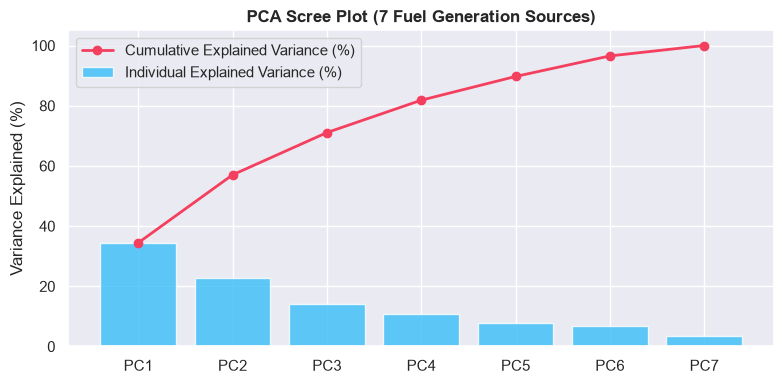

In [2]:
df = load_clean_data('../data/processed/grid_telemetry_clean.csv')
pca_res = fit_pca_pipeline(df)
print(pca_res['interpretation'])

# Scree Plot
plt.figure(figsize=(8, 4))
pcs = [f'PC{i+1}' for i in range(len(pca_res['explained_variance_ratio']))]
var_pct = [v * 100 for v in pca_res['explained_variance_ratio']]
cum_pct = [c * 100 for c in pca_res['cumulative_variance_ratio']]
plt.bar(pcs, var_pct, color='#38BDF8', alpha=0.8, label='Individual Explained Variance (%)')
plt.plot(pcs, cum_pct, color='#F43F5E', marker='o', lw=2, label='Cumulative Explained Variance (%)')
plt.title('PCA Scree Plot (7 Fuel Generation Sources)', fontsize=12, fontweight='bold')
plt.ylabel('Variance Explained (%)')
plt.legend()
plt.tight_layout()
plt.show()

## 2. Eigenvector Loadings Matrix & 2D Biplot (Unit IV)
Inspecting fuel loadings on PC1 and PC2, confirming that Coal and Gas peakers load in the opposite direction of clean renewables.

PCA Loadings Matrix:


,PC1,PC2
Coal,0.565115,0.049878
Gas (Peaker),0.435327,0.370723
Biomass,0.454845,-0.193834
Solar PV,0.105208,0.276688
Wind,-0.398766,-0.338320
Nuclear,0.256292,-0.517649
Hydro,-0.220189,0.602933


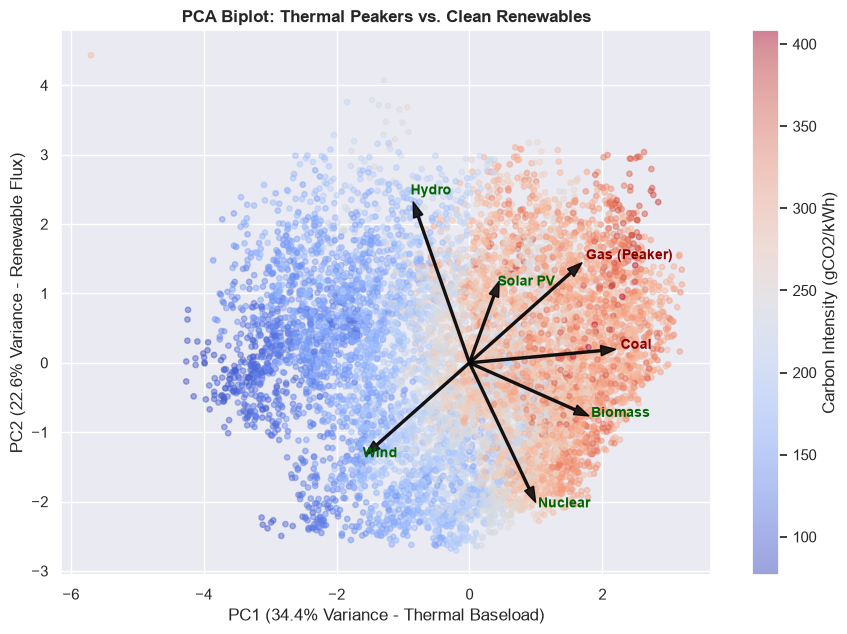

In [3]:
print('PCA Loadings Matrix:')
display(pca_res['loadings_df'])

# 2D Biplot
fig, ax = plt.subplots(figsize=(9, 6.5))
coords = pca_res['coords_2d']
ci = df['carbon_intensity_gco2_per_kwh'].values
sc = ax.scatter(coords[:, 0], coords[:, 1], c=ci, cmap='coolwarm', alpha=0.45, s=15)
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label('Carbon Intensity (gCO2/kWh)')

vectors = compute_biplot_vectors(pca_res, scale_factor=3.5)
for vec in vectors:
    vx, vy, name = vec['vx'], vec['vy'], vec['feature']
    ax.arrow(0, 0, vx, vy, color='black', alpha=0.85, width=0.03, head_width=0.15)
    ax.text(vx * 1.15, vy * 1.15, name, fontsize=10, fontweight='bold',
            color='darkred' if 'Coal' in name or 'Gas' in name else 'darkgreen')

ax.set_title('PCA Biplot: Thermal Peakers vs. Clean Renewables', fontsize=12, fontweight='bold')
ax.set_xlabel(f"PC1 ({pca_res['explained_variance_ratio'][0]*100:.1f}% Variance - Thermal Baseload)")
ax.set_ylabel(f"PC2 ({pca_res['explained_variance_ratio'][1]*100:.1f}% Variance - Renewable Flux)")
plt.tight_layout()
plt.show()

## 3. Pandas Aggregations & GroupBy Analysis (Unit V)
Exploring demand and emissions across diurnal hours and seasonal cycles.

In [4]:
hourly_summary = df.groupby('hour').agg({
    'grid_load_mw': ['mean', 'std'],
    'carbon_intensity_gco2_per_kwh': ['mean', 'min', 'max'],
    'gen_solar_mw': 'mean',
    'gen_wind_mw': 'mean',
})
display(hourly_summary.head(6))

tariff_field = 'tariff_inr_per_kwh' if 'tariff_inr_per_kwh' in df.columns else 'tariff_usd_per_kwh'
seasonal_summary = df.groupby('season').agg({
    'grid_load_mw': 'mean',
    'temperature_c': 'mean',
    'carbon_intensity_gco2_per_kwh': 'mean',
    tariff_field: 'mean',
})
display(seasonal_summary)

grid_load_mw              carbon_intensity_gco2_per_kwh                 \
              mean          std                          mean    min     max   
hour                                                                           
0     26487.167123  1791.327831                    237.635836  81.88  407.02   
1     24857.265205  1843.373341                    234.522137  81.60  408.26   
2     23652.394521  1540.451981                    233.085123  82.44  396.59   
3     23144.775342  1514.599878                    232.015836  86.79  383.26   
4     22979.756849  1796.361744                    232.878438  88.14  384.77   
5     23289.447945  1984.709371                    236.818685  88.77  389.67   

     gen_solar_mw  gen_wind_mw  
             mean         mean  
hour                            
0      211.838356  5974.150685  
1      188.761644  5872.312329  
2      168.479452  5740.578082  
3      151.016438  5622.358904  
4      136.778082  5511.906849  
5      118.739726  5432.906849

,grid_load_mw,temperature_c,carbon_intensity_gco2_per_kwh,tariff_inr_per_kwh
season,,,,
Fall,28926.513181,16.970493,265.643497,9.665217
Spring,28506.461826,14.123233,200.578469,9.671273
Summer,29331.753170,24.168264,245.473324,9.669837
Winter,29664.319676,8.688751,236.573287,9.663426


## 4. Binary Classification for Peak Grid Stress Alerts (Unit V)
Predicting impending grid stress congestion (`grid_stress_label`) using `StandardScaler` and balanced classification.

Accuracy:  90.98%
Precision: 73.42%
Recall:    95.29%
F1-Score:  82.94%
ROC-AUC:   0.9809


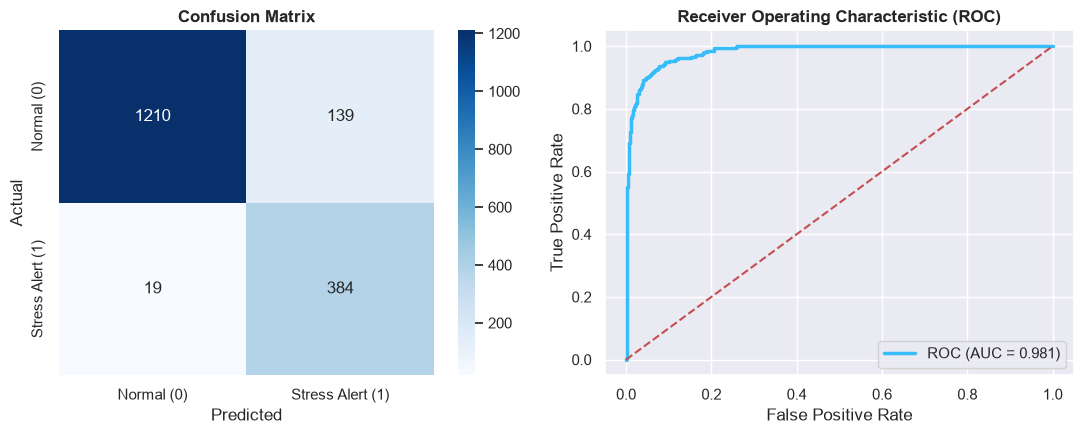

In [5]:
clf_res = train_evaluate_classifier(df)
print(f"Accuracy:  {clf_res['accuracy']*100:.2f}%")
print(f"Precision: {clf_res['precision']*100:.2f}%")
print(f"Recall:    {clf_res['recall']*100:.2f}%")
print(f"F1-Score:  {clf_res['f1']*100:.2f}%")
print(f"ROC-AUC:   {clf_res['roc_auc']:.4f}")

# Confusion Matrix Heatmap
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.heatmap(clf_res['confusion_matrix'], annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Normal (0)', 'Stress Alert (1)'], yticklabels=['Normal (0)', 'Stress Alert (1)'])
axes[0].set_title('Confusion Matrix', fontweight='bold')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# ROC Curve
fpr, tpr, _ = roc_curve(clf_res['y_true'], clf_res['y_proba'])
axes[1].plot(fpr, tpr, color='#38BDF8', lw=2.5, label=f"ROC (AUC = {clf_res['roc_auc']:.3f})")
axes[1].plot([0, 1], [0, 1], 'r--', lw=1.5)
axes[1].set_title('Receiver Operating Characteristic (ROC)', fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend()
plt.tight_layout()
plt.show()